# Exploração quantitativa

[▶ Abrir este notebook no Google Colab](https://colab.research.google.com/github/lalvim/disciplina_computacao_aplicada_humanidades_digitais/blob/main/unidade_04/01_exploracao_quantitativa.ipynb)

O guia definiu que explorar exige separar cálculo, interpretação e hipótese. Este
notebook inicia essa prática pela classificação das variáveis, porque a escala de
cada uma determina quais resumos e comparações são defensáveis.

## Tipos de variáveis

Uma **variável** é uma característica registrada para cada unidade de observação.
Neste corpus, por exemplo, cada linha representa um documento e `genero`, `ano` e
`palavras` são variáveis desse documento. Para escolher resumos e gráficos, não basta
observar como o valor foi armazenado no arquivo: é necessário perguntar o que ele
significa para a pesquisa.

![A hierarquia divide os tipos de dados em categóricos, numéricos e temporais; categóricos se dividem em nominal e ordinal, numéricos em intervalar e razão, e temporais em datas e horários.](imagens/01_tipos_variaveis.svg)

A figura adota a seguinte hierarquia didática:

| Família | Subtipo | O que o subtipo permite afirmar | Exemplo |
|---|---|---|---|
| categóricos | nominal | os valores distinguem categorias, mas não estabelecem uma ordem | `genero`, `local` e `tema` |
| categóricos | ordinal | as categorias possuem ordem, mas a distância entre elas não é conhecida | estado de conservação: baixo, médio, alto |
| numéricos | intervalar | diferenças são comparáveis, mas o zero é convencional e não expressa ausência | um escore padronizado sem zero absoluto |
| numéricos | razão | diferenças e proporções são interpretáveis porque zero significa ausência da quantidade | `palavras`, `pessoas` e `paginas` |
| temporais | datas | os valores situam eventos no calendário e permitem ordenação e, com cautela, duração | `ano` ou uma data completa |
| temporais | horários | os valores situam ocorrências no ciclo diário | horário de publicação ou registro |

Esta base possui exemplos nominais, de razão e temporais. Os casos ordinal,
intervalar e horário aparecem na tabela como possibilidades conceituais, não como
colunas existentes em `documentos.csv`.

Há ainda duas cautelas importantes:

- **discreto ou contínuo** é uma distinção complementar entre os valores numéricos,
  não uma substituição para intervalar ou razão; `palavras`, por exemplo, é ao mesmo
  tempo uma contagem discreta e uma variável de razão;
- um **identificador**, como `id_documento`, exerce um papel técnico. Mesmo que seja
  armazenado como número, não é uma medida e não deve ser somado nem receber média.

Datas e horários também exigem decisões contextuais. Subtrair anos pode representar
uma duração, mas o ano zero do calendário não transforma `ano` em variável de razão;
horários do dia são cíclicos, de modo que 23h e 0h estão próximos apesar dos números.
Assim, `dtype` não determina a classificação conceitual da variável. A distinção
entre escalas nominal, ordinal, intervalar e de razão segue Stevens (1946); aqui,
datas e horários são destacados como uma família operacional por exigirem tratamento
temporal próprio.

In [1]:
# @title Preparação do ambiente — execute esta célula no Google Colab
from pathlib import Path
import importlib.util
import os
import subprocess
import sys

URL_REPOSITORIO = 'https://github.com/lalvim/disciplina_computacao_aplicada_humanidades_digitais.git'
REPOSITORIO = Path(
    "/content/disciplina_computacao_aplicada_humanidades_digitais"
)
PASTA_UNIDADE = REPOSITORIO / 'unidade_04'

try:
    import google.colab  # type: ignore  # noqa: F401
    EM_COLAB = True
except ImportError:
    EM_COLAB = False

if EM_COLAB:
    if not (REPOSITORIO / ".git").exists():
        subprocess.run(
            [
                "git",
                "clone",
                "--depth",
                "1",
                "--branch",
                "main",
                URL_REPOSITORIO,
                str(REPOSITORIO),
            ],
            check=True,
        )

    PACOTES_COLAB = []
    ausentes = [
        especificacao
        for modulo, especificacao in PACOTES_COLAB
        if importlib.util.find_spec(modulo) is None
    ]
    if ausentes:
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", *ausentes],
            check=True,
        )

    os.chdir(PASTA_UNIDADE)
    print("Ambiente preparado em:", Path.cwd())
else:
    print("Ambiente local: nenhuma clonagem necessária.")

Ambiente local: nenhuma clonagem necessária.


In [2]:
import pandas as pd
import numpy as np
import sys
from pathlib import Path
from IPython.display import display
sys.path.insert(0, str(Path.cwd())) if str(Path.cwd()) not in sys.path else None
from graficos import distribuicao_anotada

dados = pd.read_csv("dados/documentos.csv")
pd.DataFrame(
    [
        ["genero", "na base", "categórico", "nominal", "categorias sem ordem"],
        ["estado_conservacao", "exemplo", "categórico", "ordinal", "categorias ordenadas"],
        ["escore_padronizado", "exemplo", "numérico", "intervalar", "zero convencional"],
        ["palavras", "na base", "numérico", "razão", "contagem discreta com zero significativo"],
        ["ano", "na base", "temporal", "data", "posição no calendário"],
        ["hora_publicacao", "exemplo", "temporal", "horário", "posição no ciclo diário"],
        ["id_documento", "na base", "papel técnico", "identificador", "distingue documentos"],
    ],
    columns=["variavel", "origem", "familia", "subtipo", "por_que"],
)

,variavel,origem,familia,subtipo,por_que
0,genero,na base,categórico,nominal,categorias sem ordem
1,estado_conservacao,exemplo,categórico,ordinal,categorias ordenadas
2,escore_padronizado,exemplo,numérico,intervalar,zero convencional
3,palavras,na base,numérico,razão,contagem discreta com zero significativo
4,ano,na base,temporal,data,posição no calendário
5,hora_publicacao,exemplo,temporal,horário,posição no ciclo diário
6,id_documento,na base,papel técnico,identificador,distingue documentos


A classificação anterior determina quais operações são conceitualmente
adequadas. Para variáveis nominais, como `tema` e `genero`, começaremos descrevendo
quantos documentos pertencem a cada categoria e que parcela do corpus representam.

## Frequências e proporções

Se $x_i$ é a categoria do documento $i$, a frequência absoluta da categoria
$k$ e sua proporção são:

$$
f_k = \sum_{i=1}^{n}\mathbf{1}(x_i=k),
\qquad
p_k = \frac{f_k}{n}.
$$

| Símbolo | Significado | Operação em Python |
|---|---|---|
| $n$ | total de documentos incluídos | `len(dados)` |
| $f_k$ | documentos cuja categoria é $k$ | `value_counts()` |
| $p_k$ | parcela do total na categoria $k$ | `value_counts(normalize=True)` |

A função indicadora $\mathbf{1}(x_i=k)$ vale 1 quando o documento pertence à
categoria e 0 caso contrário. Declare sempre $n$: documentos não medem
automaticamente intensidade, importância histórica ou quantidade de menções.

In [3]:
frequencias_tema = dados["tema"].value_counts().rename("frequencia")
proporcoes_tema = dados["tema"].value_counts(normalize=True).rename("proporcao")
pd.concat([frequencias_tema, proporcoes_tema], axis=1)

,frequencia,proporcao
tema,,
educação,6,0.25
trabalho,6,0.25
progresso,6,0.25
saúde,6,0.25


Frequências e proporções resumem categorias. Quando a variável registra uma
quantidade, como o número de palavras, precisamos primeiro perguntar onde os valores
se concentram. Essa pergunta introduz as medidas de tendência central.

## Medidas de tendência central

Medidas de tendência central resumem uma distribuição por um valor considerado
central ou típico. Elas não são intercambiáveis.

### Média

Para valores quantitativos $x_1,\ldots,x_n$, a média aritmética é a soma dividida
pelo número de observações:

$$
\bar{x}=\frac{1}{n}\sum_{i=1}^{n}x_i.
$$

A média funciona como ponto de equilíbrio da distribuição e usa todos os valores.
Por isso, é sensível a valores extremos. Ela é adequada quando somar os valores e
dividir igualmente o total entre as unidades possui interpretação substantiva. Não
faz sentido calcular a média de identificadores ou de categorias nominais.

### Mediana

A mediana é o valor central depois de ordenar as observações. Se $n$ for par, usa-se
a média dos dois valores centrais:

$$
\widetilde{x}=
\begin{cases}
x_{((n+1)/2)}, & n \text{ ímpar},\\[4pt]
\dfrac{x_{(n/2)}+x_{(n/2+1)}}{2}, & n \text{ par}.
\end{cases}
$$

Ela depende da posição, não da distância de todos os valores ao centro, e tende a
ser menos sensível a extremos. É especialmente informativa em distribuições
assimétricas, mas não substitui a inspeção da distribuição.

### Moda

A moda é o valor ou categoria de maior frequência. Pode ser usada também com
variáveis nominais, para as quais média e mediana não são adequadas. Uma distribuição
pode ter uma moda, várias modas ou nenhuma moda informativa. Se todos os valores
aparecem uma vez, o `pandas` devolve todos em `mode()`; escolher apenas o primeiro
criaria uma falsa moda única.

| Medida | Pergunta resumida | Sensibilidade ou limite |
|---|---|---|
| média | qual seria a parcela igual do total por unidade? | usa todos os valores e responde fortemente a extremos |
| mediana | qual valor ocupa o centro da ordenação? | não expressa as distâncias entre todos os casos |
| moda | qual valor ou categoria ocorre mais vezes? | pode ser múltipla ou não informativa |

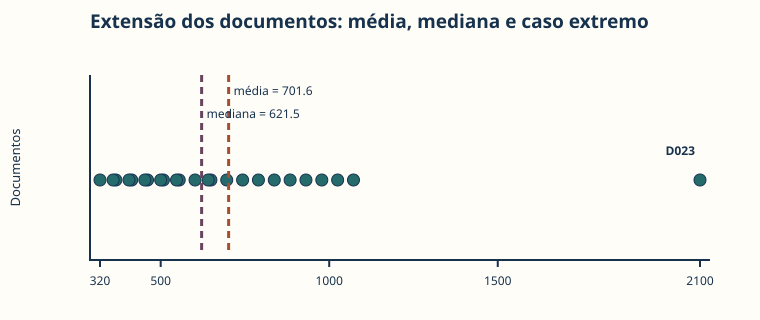

n                                                            24
media                                                701.583333
mediana                                                   621.5
frequencia_da_moda                                            1
moda_informativa      nenhuma: todos os valores ocorrem uma vez
dtype: object

In [4]:
x = dados["palavras"]
frequencias_palavras = x.value_counts()
frequencia_maxima = int(frequencias_palavras.max())
valores_modais = sorted(frequencias_palavras[frequencias_palavras.eq(frequencia_maxima)].index.tolist())
moda_informativa = valores_modais if frequencia_maxima > 1 else "nenhuma: todos os valores ocorrem uma vez"

resumo_tendencia = pd.Series({
    "n": x.count(),
    "media": x.mean(),
    "mediana": x.median(),
    "frequencia_da_moda": frequencia_maxima,
    "moda_informativa": moda_informativa,
})

display(distribuicao_anotada(
    x.tolist(), dados["id_documento"].tolist(), x.mean(), x.median()
))
resumo_tendencia

A média e a mediana localizam o centro; a moda examina repetição. Nenhuma delas
informa quanto os valores se afastam entre si. Para distinguir distribuições com o
mesmo centro, precisamos acrescentar medidas de dispersão.

## Medidas de dispersão

A **amplitude** é a distância entre máximo e mínimo. Usa apenas os dois extremos:

$$
A=x_{\max}-x_{\min}.
$$

Os quartis $Q_1$ e $Q_3$ delimitam a metade central dos valores ordenados. O intervalo
interquartil é:

$$
IQR=Q_3-Q_1.
$$

A variância amostral calcula a média corrigida dos desvios quadráticos em relação à
média; o desvio-padrão retorna à unidade original:

$$
s^2=\frac{1}{n-1}\sum_{i=1}^{n}(x_i-\bar{x})^2,
\qquad
s=\sqrt{s^2}.
$$

Variância fica em unidades ao quadrado e é menos intuitiva para descrição direta. O
desvio-padrão fica na mesma unidade de $x$, mas ambos são sensíveis a extremos. IQR é
mais resistente porque depende da metade central. O denominador $n-1$ corresponde a
`ddof=1`; para descrever uma população integral com denominador $n$, declare `ddof=0`.

In [5]:
q1 = x.quantile(0.25, interpolation="linear")
q3 = x.quantile(0.75, interpolation="linear")
resumo_dispersao = pd.Series({
    "minimo": x.min(),
    "maximo": x.max(),
    "amplitude": x.max() - x.min(),
    "q1": q1,
    "q3": q3,
    "iqr": q3 - q1,
    "variancia_amostral": x.var(ddof=1),
    "desvio_padrao_amostral": x.std(ddof=1),
})
resumo_dispersao

minimo                       320.000000
maximo                      2100.000000
amplitude                   1780.000000
q1                           459.000000
q3                           848.750000
iqr                          389.750000
variancia_amostral        138786.949275
desvio_padrao_amostral       372.541205
dtype: float64

As medidas de dispersão quantificam afastamentos, mas ainda não mostram onde
cada observação aparece nem por que um caso se afasta. A próxima etapa usa quartis e
IQR para localizar candidatos à inspeção na distribuição.

## Distribuição e valores extremos

Retome o $IQR$ calculado na seção anterior: ele cobre a metade central dos
valores ordenados e fornece uma regra convencional para localizar casos afastados.

A regra usada pelo boxplot define dois limites:

$$
L_{\mathrm{inferior}}=Q_1-1{,}5\,IQR,
\qquad
L_{\mathrm{superior}}=Q_3+1{,}5\,IQR.
$$

Um caso fora desses limites é um candidato à inspeção, nunca uma exclusão
automática ou prova de erro. Quartis possuem convenções de cálculo diferentes;
neste notebook registramos explicitamente a interpolação linear usada pelo pandas.

In [6]:
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

extremos = dados[
    (dados["palavras"] < limite_inferior)
    | (dados["palavras"] > limite_superior)
]
print("Limites:", limite_inferior, "a", limite_superior)
extremos[["id_documento", "palavras", "genero", "tema"]]

Limites: -125.625 a 1433.375


,id_documento,palavras,genero,tema
22,D023,2100,notícia,progresso


Até aqui descrevemos uma variável por vez. Para investigar se a composição
dos temas muda entre gêneros documentais, precisamos cruzar duas variáveis
categóricas e tornar explícito o denominador de cada comparação.

## Tabela de contingência

Se $A$ representa o gênero e $B$ o tema, a célula $n_{ij}$ conta os
documentos que pertencem simultaneamente à linha $i$ e à coluna $j$:

$$
n_{ij}=\sum_{r=1}^{n}\mathbf{1}(A_r=i \land B_r=j).
$$

A proporção por linha usa como denominador o total daquela linha:

$$
p_{j\mid i}=\frac{n_{ij}}{\sum_j n_{ij}}.
$$

Assim, contagens e proporções por linha respondem perguntas diferentes.
`normalize="index"` implementa $p_{j\mid i}$. Um padrão descritivo não é teste,
explicação causal ou evidência automática de associação histórica.

In [7]:
contagens = pd.crosstab(dados["genero"], dados["tema"])
proporcoes_por_genero = pd.crosstab(
    dados["genero"], dados["tema"], normalize="index"
).round(3)
contagens, proporcoes_por_genero

(tema       educação  progresso  saúde  trabalho
 genero                                         
 carta             2          2      2         2
 editorial         2          2      2         2
 notícia           2          2      2         2,
 tema       educação  progresso  saúde  trabalho
 genero                                         
 carta          0.25       0.25   0.25      0.25
 editorial      0.25       0.25   0.25      0.25
 notícia        0.25       0.25   0.25      0.25)

## Aplicação ao projeto Goodreads

As células seguintes repetem as operações do notebook com a base derivada da
Unidade 3. A especificação principal de gênero da autoria é **E2** (rótulo
original, excluindo os 1.274 livros com rótulo duvidoso). E1 (rótulo original)
e E3 (duvidosos reclassificados como feminino) aparecem como sensibilidade.
Cada tabela informa a especificação e o denominador.

In [8]:
# Localiza a pasta do projeto Goodreads (localmente ou no Colab, se a pasta for enviada para /content)
import sys
from pathlib import Path

CANDIDATOS = [Path("../projeto_goodreads"), Path("projeto_goodreads"), Path("/content/projeto_goodreads")]
PROJETO = next((c.resolve() for c in CANDIDATOS if (c / "preparar_base.py").exists()), None)
if PROJETO is None:
    raise FileNotFoundError(
        "Pasta projeto_goodreads não encontrada. Coloque-a ao lado das pastas unidade_0X "
        "ou, no Colab, envie-a para /content."
    )
if str(PROJETO) not in sys.path:
    sys.path.insert(0, str(PROJETO))
print("Projeto localizado:", (PROJETO / "preparar_base.py").exists())
from preparar_base import carregar_base_analitica
import numpy as np
import pandas as pd
from IPython.display import display

base = carregar_base_analitica()
ESPEC = {"E1 original": "genero_E1_original",
         "E2 sem duvidosos (principal)": "genero_E2_sem_duvidosos",
         "E3 reclassificada": "genero_E3_reclassificado"}
GRUPO = "genero_E2_sem_duvidosos"   # especificação principal
e2 = base[base[GRUPO].notna()].copy()
print("Livros na base:", len(base), "| livros na especificação principal (E2):", len(e2))

Projeto localizado: True
Livros na base: 10454 | livros na especificação principal (E2): 9180


**Classificação das variáveis do projeto.**

In [9]:
pd.DataFrame(
    [
        ["genero_E2_sem_duvidosos", "categórico", "nominal", "grupo comparado; feminino ou masculino"],
        ["genero_1", "categórico", "nominal", "gênero literário principal, sem ordem"],
        ["periodo_publicacao", "categórico", "ordinal", "faixas de anos ordenadas, com larguras diferentes"],
        ["n_avaliacoes", "numérico", "razão", "contagem discreta; zero significaria nenhuma avaliação"],
        ["n_resenhas", "numérico", "razão", "contagem discreta com zero possível"],
        ["taxa_resenhas", "numérico", "razão", "proporção de resenhas por avaliação"],
        ["nota_livro", "numérico", "intervalar (tratamento usual)", "média de estrelas de 1 a 5; não há zero"],
        ["paginas", "numérico", "razão", "contagem de páginas da edição"],
        ["ano_publicacao", "temporal", "data (ano)", "posição no calendário; negativo = a.C."],
        ["id_livro", "papel técnico", "identificador", "não é medida; não recebe média"],
    ],
    columns=["variavel", "familia", "subtipo", "por_que"],
)

,variavel,familia,subtipo,por_que
0,genero_E2_sem_duvidosos,categórico,nominal,grupo comparado; feminino ou masculino
1,genero_1,categórico,nominal,"gênero literário principal, sem ordem"
2,periodo_publicacao,categórico,ordinal,"faixas de anos ordenadas, com larguras diferentes"
3,n_avaliacoes,numérico,razão,contagem discreta; zero significaria nenhuma a...
4,n_resenhas,numérico,razão,contagem discreta com zero possível
5,taxa_resenhas,numérico,razão,proporção de resenhas por avaliação
6,nota_livro,numérico,intervalar (tratamento usual),média de estrelas de 1 a 5; não há zero
7,paginas,numérico,razão,contagem de páginas da edição
8,ano_publicacao,temporal,data (ano),posição no calendário; negativo = a.C.
9,id_livro,papel técnico,identificador,não é medida; não recebe média


**Frequências e proporções do grupo comparado nas três especificações** (denominador: 10.454 livros).

In [10]:
frequencias = pd.DataFrame({
    nome: base[coluna].value_counts(dropna=False) for nome, coluna in ESPEC.items()
}).rename(index=lambda x: "excluído (duvidoso)" if pd.isna(x) else x)
proporcoes = (frequencias / len(base)).round(3)
display(frequencias)
display(proporcoes)
print("Denominador n =", len(base), "livros")

,E1 original,E2 sem duvidosos (principal),E3 reclassificada
feminino,4638.0,4638,5912.0
masculino,5816.0,4542,4542.0
excluído (duvidoso),NaN,1274,NaN


,E1 original,E2 sem duvidosos (principal),E3 reclassificada
feminino,0.444,0.444,0.566
masculino,0.556,0.434,0.434
excluído (duvidoso),NaN,0.122,NaN


Denominador n = 10454 livros


**Centro e dispersão por grupo** (E2; quartis com interpolação linear; desvio-padrão com `ddof=1`).

In [11]:
def resumo(serie):
    q1, q3 = serie.quantile([0.25, 0.75], interpolation="linear")
    return pd.Series({
        "n": serie.count(), "media": serie.mean(), "mediana": serie.median(),
        "q1": q1, "q3": q3, "iqr": q3 - q1,
        "desvio_padrao": serie.std(ddof=1), "minimo": serie.min(), "maximo": serie.max(),
    })

for variavel in ["n_avaliacoes", "n_resenhas", "taxa_resenhas", "nota_livro"]:
    print(f"\n{variavel} por grupo (E2):")
    display(e2.groupby(GRUPO)[variavel].apply(resumo).unstack().round(3))


n_avaliacoes por grupo (E2):


,n,media,mediana,q1,q3,iqr,desvio_padrao,minimo,maximo
genero_E2_sem_duvidosos,,,,,,,,,
feminino,4638.0,29505.824,3129.0,747.25,13003.0,12255.75,140788.677,6.0,3819418.0
masculino,4542.0,46386.601,5217.5,1133.75,23219.5,22085.75,170611.980,5.0,3203463.0



n_resenhas por grupo (E2):


,n,media,mediana,q1,q3,iqr,desvio_padrao,minimo,maximo
genero_E2_sem_duvidosos,,,,,,,,,
feminino,4638.0,1747.938,320.0,105.00,1143.00,1038.0,5739.042,0.0,126452.0
masculino,4542.0,2034.114,360.5,97.25,1390.25,1293.0,5883.268,0.0,147696.0



taxa_resenhas por grupo (E2):


,n,media,mediana,q1,q3,iqr,desvio_padrao,minimo,maximo
genero_E2_sem_duvidosos,,,,,,,,,
feminino,4638.0,0.145,0.114,0.071,0.181,0.109,0.115,0.0,1.000
masculino,4542.0,0.109,0.076,0.044,0.136,0.092,0.104,0.0,0.911



nota_livro por grupo (E2):


,n,media,mediana,q1,q3,iqr,desvio_padrao,minimo,maximo
genero_E2_sem_duvidosos,,,,,,,,,
feminino,4638.0,3.922,3.93,3.74,4.11,0.37,0.287,1.85,5.0
masculino,4542.0,3.972,3.99,3.80,4.16,0.36,0.289,2.14,5.0


In [12]:
# Moda: útil para categorias, pouco informativa para contagens grandes
print("Gênero literário modal por grupo (E2):")
display(e2.groupby(GRUPO)["genero_1"].agg(lambda s: s.value_counts().index[0]))
freq_max = e2["n_avaliacoes"].value_counts().max()
print("Frequência máxima de um mesmo valor de n_avaliacoes:", int(freq_max), "livros")

Gênero literário modal por grupo (E2):


genero_E2_sem_duvidosos
feminino     Romance
masculino    Fiction
Name: genero_1, dtype: object

Frequência máxima de um mesmo valor de n_avaliacoes: 14 livros


**Valores extremos pela regra de 1,5 IQR**, na escala original e na escala logarítmica.

In [13]:
x = e2["n_avaliacoes"]
q1, q3 = x.quantile([0.25, 0.75], interpolation="linear")
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
sinalizados = e2[(x < lim_inf) | (x > lim_sup)]
print(f"Escala original: limites {lim_inf:.1f} a {lim_sup:.1f}; sinalizados: {len(sinalizados)} livros ({len(sinalizados)/len(e2):.1%})")

lx = e2["log10_avaliacoes"]
lq1, lq3 = lx.quantile([0.25, 0.75], interpolation="linear")
liqr = lq3 - lq1
llim_inf, llim_sup = lq1 - 1.5 * liqr, lq3 + 1.5 * liqr
sinalizados_log = e2[(lx < llim_inf) | (lx > llim_sup)]
print(f"Escala log10: limites {10**llim_inf:.0f} a {10**llim_sup:.0f} avaliações; sinalizados: {len(sinalizados_log)} livros")
display(sinalizados_log.groupby(GRUPO).size().rename("sinalizados_escala_log"))
sinalizados_log.nlargest(8, "n_avaliacoes")[["titulo", "autor", GRUPO, "ano_publicacao", "genero_1", "n_avaliacoes", "n_resenhas"]]

Escala original: limites -23433.4 a 41439.6; sinalizados: 1329 livros (14.5%)
Escala log10: limites 11 a 1433051 avaliações; sinalizados: 46 livros


genero_E2_sem_duvidosos
feminino     18
masculino    28
Name: sinalizados_escala_log, dtype: int64

,titulo,autor,genero_E2_sem_duvidosos,ano_publicacao,genero_1,n_avaliacoes,n_resenhas
579,To Kill a Mockingbird,Harper Lee,feminino,1960,Classics,3819418,81096
578,The Great Gatsby,F. Scott Fitzgerald,masculino,1925,Classics,3203463,57844
2276,The Fault in Our Stars,John Green,masculino,2012,Young Adult,2946242,147696
2047,Pride and Prejudice,Jane Austen,feminino,1813,Classics,2504844,55329
5611,1984,George Orwell,masculino,1949,Classics,2495963,55492
1833,The Hobbit,J.R.R. Tolkien,masculino,1937,Fantasy,2471782,42010
573,The Catcher in the Rye,J.D. Salinger,masculino,1951,Classics,2377242,50322
2510,Angels & Demons,Dan Brown,masculino,2000,Fiction,2334743,26835


**Tabelas de contingência** (12 gêneros literários principais mais frequentes; proporções por linha).

In [14]:
principais = e2["genero_1"].value_counts().head(12).index
sub = e2[e2["genero_1"].isin(principais)]
contagens = pd.crosstab(sub["genero_1"], sub[GRUPO], margins=True, margins_name="total")
por_linha = pd.crosstab(sub["genero_1"], sub[GRUPO], normalize="index").round(3)
display(contagens.sort_values("total", ascending=False))
display(por_linha.sort_values("feminino"))

# Faixas de reconhecimento (quartis de n_avaliacoes em E2) × grupo
faixa = pd.qcut(e2["n_avaliacoes"], 4, labels=["Q1 (menos avaliados)", "Q2", "Q3", "Q4 (mais avaliados)"])
print("Composição de cada faixa de avaliações (proporção por linha):")
pd.crosstab(faixa, e2[GRUPO], normalize="index").round(3)

genero_E2_sem_duvidosos,feminino,masculino,total
genero_1,,,
total,3653,3347,7000
Fiction,432,759,1191
Fantasy,675,483,1158
Romance,735,195,930
Young Adult,657,210,867
Historical,426,207,633
Nonfiction,174,296,470
Science Fiction,126,300,426
Mystery,189,153,342


genero_E2_sem_duvidosos,feminino,masculino
genero_1,,
History,0.113,0.887
Classics,0.197,0.803
Horror,0.217,0.783
Science Fiction,0.296,0.704
Fiction,0.363,0.637
Nonfiction,0.370,0.630
Sequential Art,0.529,0.471
Mystery,0.553,0.447
Fantasy,0.583,0.417


Composição de cada faixa de avaliações (proporção por linha):


genero_E2_sem_duvidosos,feminino,masculino
n_avaliacoes,,
Q1 (menos avaliados),0.554,0.446
Q2,0.542,0.458
Q3,0.505,0.495
Q4 (mais avaliados),0.420,0.580


**Sensibilidade da comparação central** às especificações de gênero e ao período.

In [15]:
# Mesma comparação central nas três especificações e no recorte 1990–2019
linhas = []
for nome, coluna in ESPEC.items():
    for recorte, dados in [("todos", base), ("1990–2019", base[base["ano_publicacao"] >= 1990])]:
        g = dados[dados[coluna].notna()].groupby(coluna)
        med = g["n_avaliacoes"].median()
        linhas.append({
            "especificação": nome, "recorte": recorte,
            "n_fem": int(g.size()["feminino"]), "n_masc": int(g.size()["masculino"]),
            "mediana_aval_fem": med["feminino"], "mediana_aval_masc": med["masculino"],
            "razao_fem_masc": med["feminino"] / med["masculino"],
            "mediana_resenhas_fem": g["n_resenhas"].median()["feminino"],
            "mediana_resenhas_masc": g["n_resenhas"].median()["masculino"],
            "mediana_taxa_fem": g["taxa_resenhas"].median()["feminino"],
            "mediana_taxa_masc": g["taxa_resenhas"].median()["masculino"],
        })
pd.DataFrame(linhas).round(3)

,especificação,recorte,n_fem,n_masc,mediana_aval_fem,mediana_aval_masc,razao_fem_masc,mediana_resenhas_fem,mediana_resenhas_masc,mediana_taxa_fem,mediana_taxa_masc
0,E1 original,todos,4638,5816,3129.0,4419.5,0.708,320.0,336.0,0.114,0.087
1,E1 original,1990–2019,4154,4183,2580.5,3061.0,0.843,290.0,296.0,0.123,0.112
2,E2 sem duvidosos (principal),todos,4638,4542,3129.0,5217.5,0.600,320.0,360.5,0.114,0.076
3,E2 sem duvidosos (principal),1990–2019,4154,2987,2580.5,3565.0,0.724,290.0,315.0,0.123,0.104
4,E3 reclassificada,todos,5912,4542,2941.0,5217.5,0.564,307.5,360.5,0.116,0.076
5,E3 reclassificada,1990–2019,5350,2987,2507.0,3565.0,0.703,283.5,315.0,0.125,0.104


A tabela de contingência encerra o movimento que começou na classificação das
variáveis: escala, pergunta e denominador precisam permanecer coerentes. A
atividade reúne essas decisões antes que os resultados sejam levados para a
exploração textual e para as visualizações.

## U04-A02 — Atividade — exploração quantitativa

Classifique variáveis; escolha e justifique ao menos uma medida de tendência central
e uma de dispersão; declare denominadores; inspecione extremo e contingência.
Separe descrição, interpretação e hipótese. Ao concluir, registre
quais resultados merecem ser comparados com o conteúdo dos textos no Notebook 02.

**Resposta (valores das células anteriores, especificação E2, n = 9.180 livros).**

**Classificação das variáveis.** O grupo comparado (`genero_E2_sem_duvidosos`)
e o gênero literário (`genero_1`) são nominais; `periodo_publicacao` é ordinal;
`n_avaliacoes`, `n_resenhas`, `taxa_resenhas` e `paginas` são de razão;
`nota_livro` é tratada como intervalar, porque varia de 1 a 5 sem zero
absoluto; `ano_publicacao` é temporal; `id_livro` é identificador e não recebe
média.

**Medidas escolhidas e justificativa.** Para as contagens, uso a **mediana**
como centro e o **intervalo interquartil (IQR)** como dispersão. A média é
dominada por poucos livros com milhões de avaliações: para livros de autoria
feminina, a média é 29.506 e a mediana 3.129; para os de autoria masculina, 46.387
e 5.218. O desvio-padrão (140.789 e 170.612) é maior que a própria média, outro
sinal de assimetria. A moda não é informativa para contagens (o valor mais
repetido aparece em só 14 livros), mas é útil para categorias: o gênero
literário modal é Romance entre os livros de autoras e Fiction entre os de
autores.

**Descrição.**
- *Denominadores:* 4.638 livros de autoria feminina e 4.542 de autoria
  masculina (E2); 1.274 excluídos por rótulo duvidoso.
- *Alcance:* mediana de 3.129 avaliações (Q1 = 747; Q3 = 13.003) para autoria
  feminina e de 5.218 (Q1 = 1.134; Q3 = 23.220) para autoria masculina. A
  mediana feminina corresponde a 60% da masculina.
- *Engajamento:* as medianas de resenhas são próximas (320 e 361). Já a
  **taxa de resenhas por avaliação** é maior nos livros de autoras (mediana de
  0,114 contra 0,076).
- *Apreciação (secundária):* notas médias quase iguais (3,92 e 3,97).
- *Extremos:* na escala original, a regra de 1,5 IQR sinaliza 1.329 livros
  (14,5%), o que mostra que a regra não serve para distribuições tão
  assimétricas. Na escala logarítmica, sinaliza 46 livros (18 de autoras, 28 de
  autores): 29 acima de cerca de 1,4 milhão de avaliações (11 de autoras), quase
  todos clássicos ou best-sellers, como *To Kill a Mockingbird* (3.819.418), e
  17 abaixo de 11 avaliações (7 de autoras), em geral livros recentes e pouco
  lidos. Nenhum foi removido.
- *Contingência:* a proporção de livros de autoras varia de 11,3% em History e
  19,7% em Classics a 75,8% em Young Adult e 79,0% em Romance (proporções por
  linha, denominador = livros de cada gênero). Entre os livros do quartil menos
  avaliado, 55,4% são de autoras; no quartil mais avaliado, 42,0%.
- *Sensibilidade:* a razão entre as medianas (feminina/masculina) é 0,71 em
  E1, 0,60 em E2 e 0,56 em E3. Restrita a livros de 1990 a 2019, sobe para 0,84,
  0,72 e 0,70. O sentido da diferença se mantém; o tamanho depende da
  especificação e do período.

**Interpretação situada.** Neste recorte, livros de autoras recebem, no
centro da distribuição, menos avaliações que livros de autores, mas geram
proporcionalmente mais resenhas por avaliação. A correção do rótulo de gênero
aumenta a diferença, porque o grupo “masculino” original continha livros
populares de autoras. Parte da diferença parece vir da composição: os livros
de autores são mais antigos e mais presentes em Classics, gênero com medianas
muito altas.

**Hipóteses provisórias.** (H1) A diferença de alcance pode estar associada à
idade dos livros e à concentração por gênero literário, e não apenas ao gênero
da autoria. (H2) A maior taxa de resenhas dos livros de autoras pode refletir
comunidades de leitores mais engajadas em certos gêneros (romance, jovem
adulto).

**Limite.** Nada disso vale para o Goodreads inteiro, nem mostra causa ou
qualidade.

**Resultados que seguem para o Notebook 02:** a concentração das autoras em
Romance e Young Adult e dos autores em History, Classics e Science Fiction, que
pode aparecer no vocabulário dos títulos, e a pergunta sobre se títulos
reproduzem marcas de gênero (como “girl” ou “war”).